# 8 Queens Problem: Genetic Algorithm (GA) vs Constraint Satisfaction Problem (CSP)

**Assignment goals**
1. Solve N-Queens using a Genetic Algorithm.
2. Solve N-Queens using CSP/backtracking.
3. Increase N and compare runtime and search effort.
4. Record the largest N solved within the limits set in this experiment.



In [3]:
import random
import time
import math
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter

RANDOM_SEED = 42
random.seed(RANDOM_SEED)

# Limits for fair, bounded experiments
GA_POPULATION = 80
GA_MAX_GENERATIONS = 2000
GA_STAGNATION_LIMIT = 350
GA_RESTARTS = 2

CSP_NODE_LIMIT = 2_000_000
CSP_TIME_LIMIT_SECONDS = 5.0

# Test small values first, then values greater than 20.
N_VALUES = [4, 8, 10, 12, 14, 16, 18, 20, 22, 24, 26, 28, 30, 32, 35, 40, 50, 75, 100]

print("Settings loaded.")
print("GA: population =", GA_POPULATION, ", max generations =", GA_MAX_GENERATIONS)
print("CSP: node limit =", CSP_NODE_LIMIT, ", time limit =", CSP_TIME_LIMIT_SECONDS, "seconds per N")

Settings loaded.
GA: population = 80 , max generations = 2000
CSP: node limit = 2000000 , time limit = 5.0 seconds per N


## 2. Helper function: count conflicts



In [4]:
def count_diagonal_conflicts(chromosome):
    # chromosome[column] = row
    main_diagonals = Counter()
    anti_diagonals = Counter()
    for col, row in enumerate(chromosome):
        main_diagonals[row - col] += 1
        anti_diagonals[row + col] += 1

    conflicts = 0
    for count in main_diagonals.values():
        conflicts += count * (count - 1) // 2
    for count in anti_diagonals.values():
        conflicts += count * (count - 1) // 2
    return conflicts


# Quick check: a known valid 8-Queens solution
known_solution = [5, 2, 0, 6, 4, 7, 1, 3]
print("Known 8-Queens solution conflicts:", count_diagonal_conflicts(known_solution))

Known 8-Queens solution conflicts: 0


## 3. Genetic Algorithm (GA)

- Create random queen arrangements.
- Keep the best arrangements (fewest diagonal conflicts).
- Use order crossover and swap mutation to make new arrangements.
- Stop when conflicts are zero or the generation/restart limits are reached.

In [5]:
def order_crossover(parent1, parent2):
    """Order crossover (OX), which keeps each row value unique."""
    n = len(parent1)
    if n < 2:
        return parent1[:]
    a, b = sorted(random.sample(range(n), 2))
    child = [-1] * n
    child[a:b+1] = parent1[a:b+1]
    used = set(child[a:b+1])
    p2_values = parent2[b+1:] + parent2[:b+1]
    fill_positions = list(range(b+1, n)) + list(range(0, a))
    values = [v for v in p2_values if v not in used]
    for pos, val in zip(fill_positions, values):
        child[pos] = val
    return child


def mutate_swap(chromosome, mutation_rate=0.25):
    child = chromosome[:]
    if len(child) >= 2 and random.random() < mutation_rate:
        i, j = random.sample(range(len(child)), 2)
        child[i], child[j] = child[j], child[i]
    return child


def genetic_algorithm(n, population_size=GA_POPULATION,
                      max_generations=GA_MAX_GENERATIONS,
                      stagnation_limit=GA_STAGNATION_LIMIT,
                      restarts=GA_RESTARTS):
    start = time.perf_counter()
    best_overall = None
    best_conflicts_overall = math.inf
    total_generations = 0
    total_evaluations = 0

    # N=1,2,3 have no solution; the assignment mainly tests N >= 4.
    if n in (2, 3):
        return {"algorithm":"GA", "N":n, "success":False, "runtime_sec":time.perf_counter()-start,
                "effort":0, "generations":0, "conflicts":None, "solution":None,
                "status":"No mathematical solution for N=2 or N=3"}

    for restart in range(restarts + 1):
        population = [random.sample(range(n), n) for _ in range(population_size)]
        best_this_restart = math.inf
        stale = 0

        for generation in range(max_generations + 1):
            scores = [count_diagonal_conflicts(ind) for ind in population]
            total_evaluations += len(population)
            order = sorted(range(len(population)), key=lambda i: scores[i])
            current_best_idx = order[0]
            current_best = scores[current_best_idx]
            total_generations += 1

            if current_best < best_conflicts_overall:
                best_conflicts_overall = current_best
                best_overall = population[current_best_idx][:]

            if current_best == 0:
                return {"algorithm":"GA", "N":n, "success":True,
                        "runtime_sec":time.perf_counter()-start, "effort":total_evaluations,
                        "generations":total_generations, "conflicts":0,
                        "solution":best_overall, "status":"Solved"}

            if current_best < best_this_restart:
                best_this_restart = current_best
                stale = 0
            else:
                stale += 1

            if generation == max_generations or stale >= stagnation_limit:
                break

            # Elitism: keep the best 2 individuals
            new_population = [population[i][:] for i in order[:2]]

            # Tournament selection and crossover
            while len(new_population) < population_size:
                def tournament():
                    candidates = random.sample(range(population_size), min(3, population_size))
                    winner = min(candidates, key=lambda idx: scores[idx])
                    return population[winner]
                p1 = tournament()
                p2 = tournament()
                child = order_crossover(p1, p2)
                child = mutate_swap(child, mutation_rate=min(0.8, 2.0 / max(2, n)))
                new_population.append(child)
            population = new_population

    return {"algorithm":"GA", "N":n, "success":False,
            "runtime_sec":time.perf_counter()-start, "effort":total_evaluations,
            "generations":total_generations, "conflicts":int(best_conflicts_overall),
            "solution":best_overall, "status":"Limit reached; no zero-conflict solution"}

## 4. CSP using backtracking and bit masks



In [6]:
class SearchLimitReached(Exception):
    pass


def csp_backtracking(n, node_limit=CSP_NODE_LIMIT, time_limit=CSP_TIME_LIMIT_SECONDS):
    start = time.perf_counter()
    deadline = start + time_limit
    nodes = 0
    solution = [-1] * n

    if n in (2, 3):
        return {"algorithm":"CSP", "N":n, "success":False,
                "runtime_sec":time.perf_counter()-start, "effort":0,
                "generations":None, "conflicts":None, "solution":None,
                "status":"No mathematical solution for N=2 or N=3"}

    # Use a bit for each column. Diagonal masks shift as we move to the next row.
    all_columns = (1 << n) - 1

    def search(row, columns, diag_left, diag_right):
        nonlocal nodes
        nodes += 1
        if nodes >= node_limit or (nodes % 4096 == 0 and time.perf_counter() >= deadline):
            raise SearchLimitReached
        if row == n:
            return True

        available = all_columns & ~(columns | diag_left | diag_right)
        while available:
            bit = available & -available
            available -= bit
            col = bit.bit_length() - 1
            solution[row] = col
            if search(row + 1,
                      columns | bit,
                      ((diag_left | bit) << 1) & all_columns,
                      (diag_right | bit) >> 1):
                return True
        return False

    try:
        found = search(0, 0, 0, 0)
        elapsed = time.perf_counter() - start
        if found:
            # CSP solution is row -> column; convert to the same column -> row format for validation.
            chromosome = [0] * n
            for row, col in enumerate(solution):
                chromosome[col] = row
            return {"algorithm":"CSP", "N":n, "success":True, "runtime_sec":elapsed,
                    "effort":nodes, "generations":None, "conflicts":count_diagonal_conflicts(chromosome),
                    "solution":solution[:], "status":"Solved"}
        return {"algorithm":"CSP", "N":n, "success":False, "runtime_sec":elapsed,
                "effort":nodes, "generations":None, "conflicts":None, "solution":None,
                "status":"Search ended without solution"}
    except SearchLimitReached:
        elapsed = time.perf_counter() - start
        reason = "Node limit reached" if nodes >= node_limit else "Time limit reached"
        return {"algorithm":"CSP", "N":n, "success":False, "runtime_sec":elapsed,
                "effort":nodes, "generations":None, "conflicts":None, "solution":None,
                "status":reason}

## 5. Test the classic 8-Queens case

This confirms both implementations can solve the original problem before testing larger N.

In [ ]:
ga_8 = genetic_algorithm(8)
csp_8 = csp_backtracking(8)

print("GA result:", {k: v for k, v in ga_8.items() if k != "solution"})
print("GA solution:", ga_8["solution"])
print("CSP result:", {k: v for k, v in csp_8.items() if k != "solution"})
print("CSP solution (row -> column):", csp_8["solution"])

GA result: {'algorithm': 'GA', 'N': 8, 'success': True, 'runtime_sec': 0.005233078000003388, 'effort': 240, 'generations': 3, 'conflicts': 0, 'status': 'Solved'}
GA solution: [2, 5, 1, 6, 0, 3, 7, 4]
CSP result: {'algorithm': 'CSP', 'N': 8, 'success': True, 'runtime_sec': 6.93889999752173e-05, 'effort': 114, 'generations': None, 'conflicts': 0, 'status': 'Solved'}
CSP solution (row -> column): [0, 4, 7, 5, 2, 6, 1, 3]


## 6. Run the full experiment for N = 4 through values above 20



In [7]:
results = []

for n in N_VALUES:
    print(f"Testing N={n} ...")
    ga_result = genetic_algorithm(n)
    csp_result = csp_backtracking(n)
    results.extend([ga_result, csp_result])

    print(f"  GA : success={ga_result['success']}, time={ga_result['runtime_sec']:.4f}s, "
          f"generations={ga_result['generations']}, conflicts={ga_result['conflicts']}, "
          f"status={ga_result['status']}")
    print(f"  CSP: success={csp_result['success']}, time={csp_result['runtime_sec']:.4f}s, "
          f"nodes={csp_result['effort']}, status={csp_result['status']}")

results_df = pd.DataFrame(results)
display_columns = ["algorithm", "N", "success", "runtime_sec", "effort", "generations", "conflicts", "status"]
results_df[display_columns].round({"runtime_sec":4}).sort_values(["N", "algorithm"])

Testing N=4 ...
  GA : success=True, time=0.0006s, generations=1, conflicts=0, status=Solved
  CSP: success=True, time=0.0000s, nodes=9, status=Solved
Testing N=8 ...
  GA : success=True, time=0.0092s, generations=6, conflicts=0, status=Solved
  CSP: success=True, time=0.0001s, nodes=114, status=Solved
Testing N=10 ...
  GA : success=True, time=0.0094s, generations=5, conflicts=0, status=Solved
  CSP: success=True, time=0.0001s, nodes=103, status=Solved
Testing N=12 ...
  GA : success=True, time=0.3512s, generations=198, conflicts=0, status=Solved
  CSP: success=True, time=0.0002s, nodes=262, status=Solved
Testing N=14 ...
  GA : success=True, time=0.0363s, generations=20, conflicts=0, status=Solved
  CSP: success=True, time=0.0011s, nodes=1900, status=Solved
Testing N=16 ...
  GA : success=True, time=0.1235s, generations=62, conflicts=0, status=Solved
  CSP: success=True, time=0.0057s, nodes=10053, status=Solved
Testing N=18 ...
  GA : success=False, time=2.8242s, generations=1190, co

,algorithm,N,success,runtime_sec,effort,generations,conflicts,status
1,CSP,4,True,0.0000,9,NaN,0.0,Solved
0,GA,4,True,0.0006,80,1.0,0.0,Solved
3,CSP,8,True,0.0001,114,NaN,0.0,Solved
2,GA,8,True,0.0092,480,6.0,0.0,Solved
5,CSP,10,True,0.0001,103,NaN,0.0,Solved
4,GA,10,True,0.0094,400,5.0,0.0,Solved
7,CSP,12,True,0.0002,262,NaN,0.0,Solved
6,GA,12,True,0.3512,15840,198.0,0.0,Solved
9,CSP,14,True,0.0011,1900,NaN,0.0,Solved
8,GA,14,True,0.0363,1600,20.0,0.0,Solved


## 7. Compare results in a clean table

- GA `effort` means fitness evaluations.
- CSP `effort` means search nodes visited.
- These effort measures are different, so compare them within each algorithm, not as identical units.

In [8]:
comparison = results_df[display_columns].copy()
comparison["runtime_sec"] = comparison["runtime_sec"].round(6)
display(comparison.sort_values(["N", "algorithm"]).reset_index(drop=True))

,algorithm,N,success,runtime_sec,effort,generations,conflicts,status
0,CSP,4,True,0.000012,9,NaN,0.0,Solved
1,GA,4,True,0.000591,80,1.0,0.0,Solved
2,CSP,8,True,0.000058,114,NaN,0.0,Solved
3,GA,8,True,0.009244,480,6.0,0.0,Solved
4,CSP,10,True,0.000067,103,NaN,0.0,Solved
5,GA,10,True,0.009407,400,5.0,0.0,Solved
6,CSP,12,True,0.000172,262,NaN,0.0,Solved
7,GA,12,True,0.351235,15840,198.0,0.0,Solved
8,CSP,14,True,0.001117,1900,NaN,0.0,Solved
9,GA,14,True,0.036307,1600,20.0,0.0,Solved


## 8. Graph 1: Runtime versus number of queens

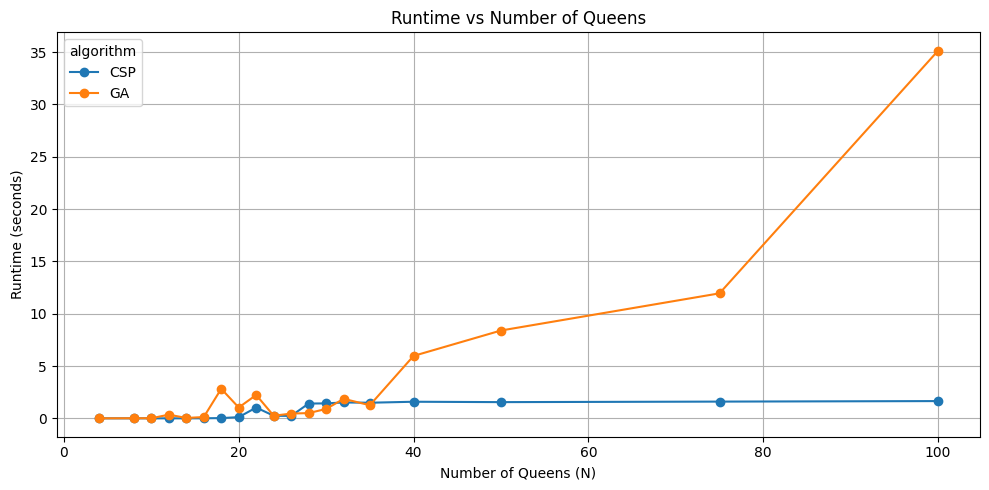

In [9]:
runtime_pivot = results_df.pivot(index="N", columns="algorithm", values="runtime_sec").sort_index()
ax = runtime_pivot.plot(marker="o", figsize=(10, 5))
ax.set_title("Runtime vs Number of Queens")
ax.set_xlabel("Number of Queens (N)")
ax.set_ylabel("Runtime (seconds)")
ax.grid(True)
plt.tight_layout()
plt.show()

## 9. Graph 2: Search effort versus number of queens

The y-axis is a count, not seconds. GA evaluations and CSP nodes are different kinds of work.

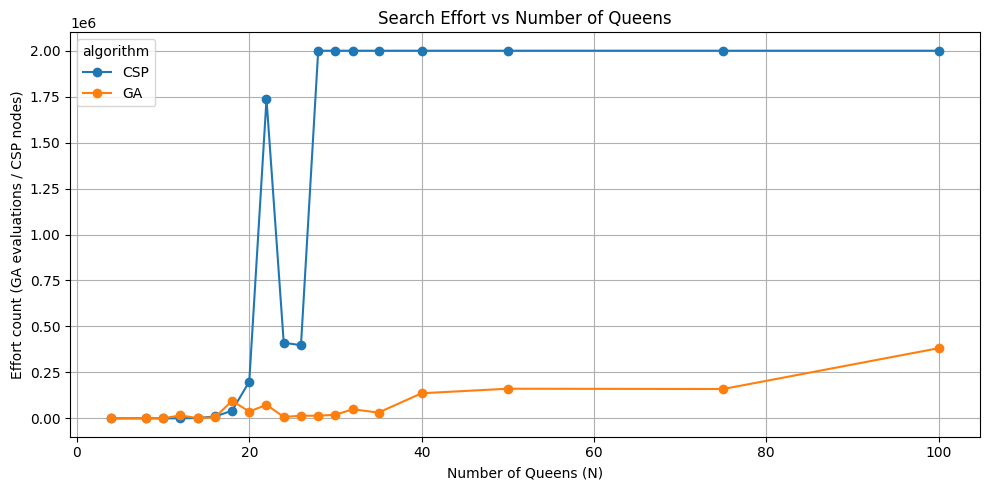

In [10]:
effort_pivot = results_df.pivot(index="N", columns="algorithm", values="effort").sort_index()
ax = effort_pivot.plot(marker="o", figsize=(10, 5))
ax.set_title("Search Effort vs Number of Queens")
ax.set_xlabel("Number of Queens (N)")
ax.set_ylabel("Effort count (GA evaluations / CSP nodes)")
ax.grid(True)
plt.tight_layout()
plt.show()

## 10. Find the largest N solved within these experiment limits

In [11]:
summary_rows = []
for algorithm in ["GA", "CSP"]:
    subset = results_df[(results_df["algorithm"] == algorithm) & (results_df["success"] == True)]
    if len(subset):
        largest_n = int(subset["N"].max())
        summary_rows.append({
            "algorithm": algorithm,
            "largest_N_solved_in_this_run": largest_n,
            "runtime_at_that_N_sec": float(subset.loc[subset["N"] == largest_n, "runtime_sec"].iloc[0]),
            "meaning": "Largest tested N solved within configured limits"
        })
    else:
        summary_rows.append({
            "algorithm": algorithm,
            "largest_N_solved_in_this_run": None,
            "runtime_at_that_N_sec": None,
            "meaning": "No tested N solved within configured limits"
        })
summary_df = pd.DataFrame(summary_rows)
display(summary_df)

,algorithm,largest_N_solved_in_this_run,runtime_at_that_N_sec,meaning
0,GA,75,11.947386,Largest tested N solved within configured limits
1,CSP,26,0.233968,Largest tested N solved within configured limits


## 11. Validate solutions

This cell checks every solution that was returned and confirms that it has zero diagonal conflicts. A solution is valid only if the conflict count is zero.

In [12]:
validation = []
for _, row in results_df.iterrows():
    sol = row["solution"]
    if row["success"] and sol is not None:
        if row["algorithm"] == "GA":
            conflicts = count_diagonal_conflicts(sol)
        else:
            # CSP stores row -> column; convert to column -> row.
            chromosome = [0] * int(row["N"])
            for r, c in enumerate(sol):
                chromosome[c] = r
            conflicts = count_diagonal_conflicts(chromosome)
        validation.append({"algorithm": row["algorithm"], "N": int(row["N"]),
                           "valid_zero_conflicts": conflicts == 0, "conflicts": conflicts})
display(pd.DataFrame(validation))

,algorithm,N,valid_zero_conflicts,conflicts
0,GA,4,True,0
1,CSP,4,True,0
2,GA,8,True,0
3,CSP,8,True,0
4,GA,10,True,0
5,CSP,10,True,0
6,GA,12,True,0
7,CSP,12,True,0
8,GA,14,True,0
9,CSP,14,True,0


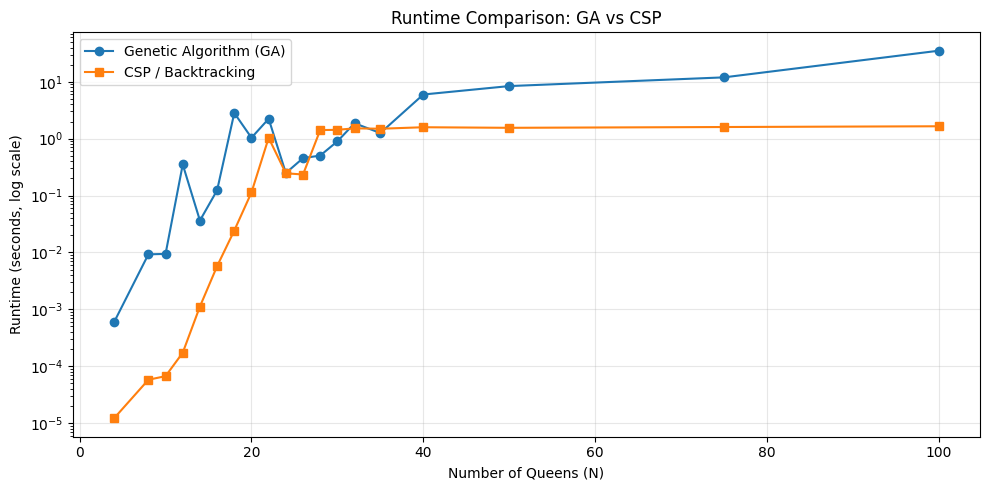

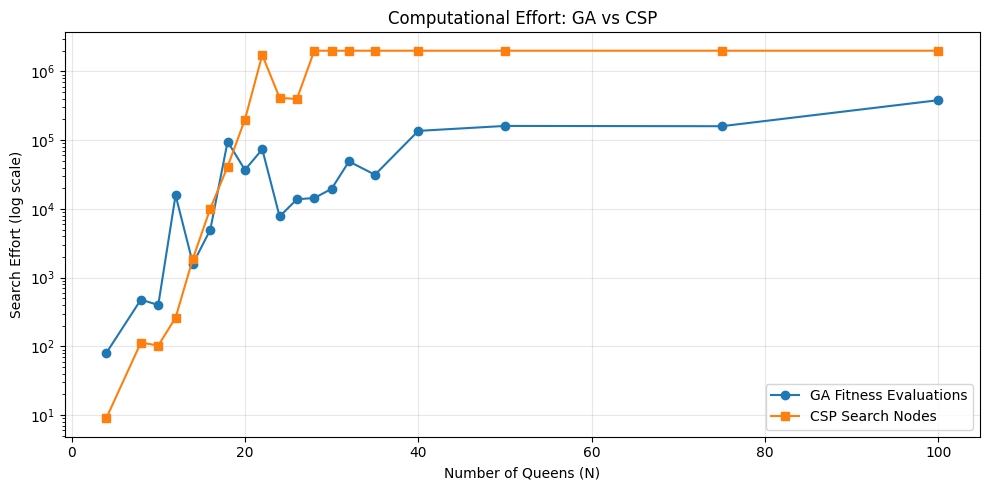

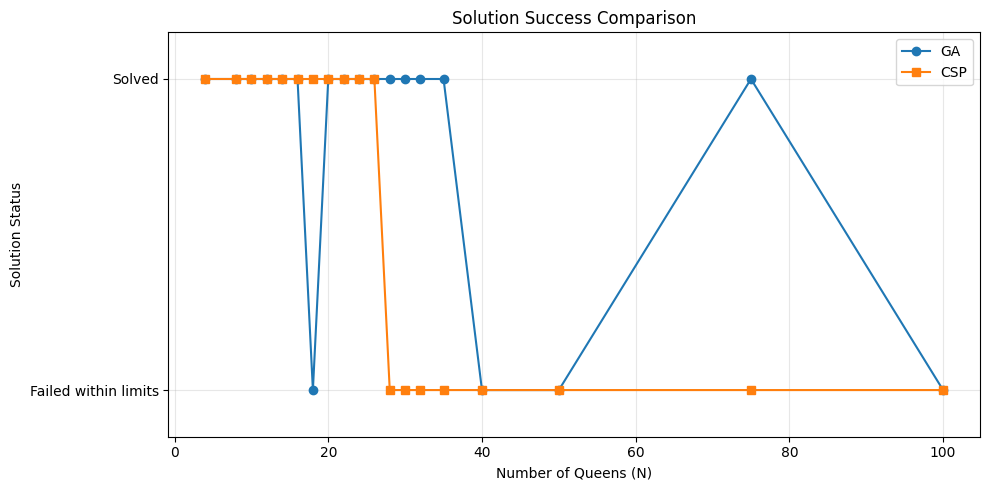

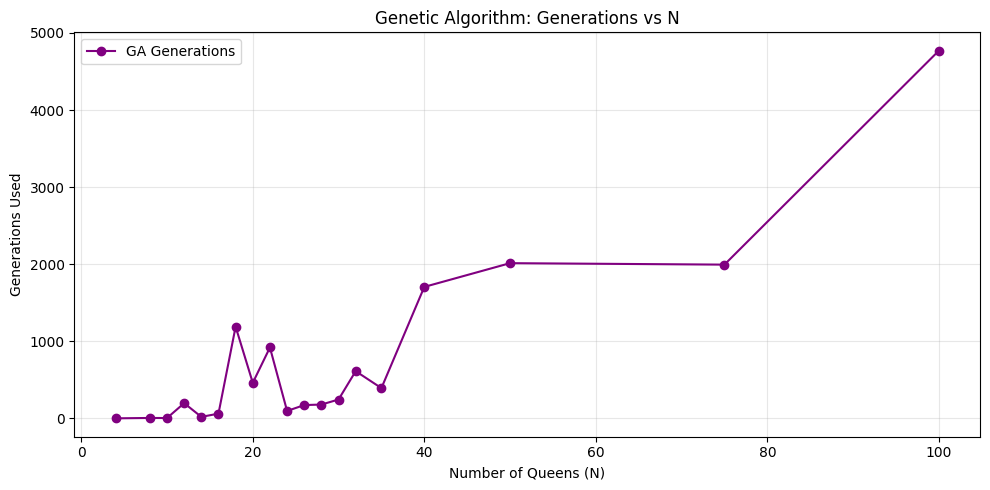

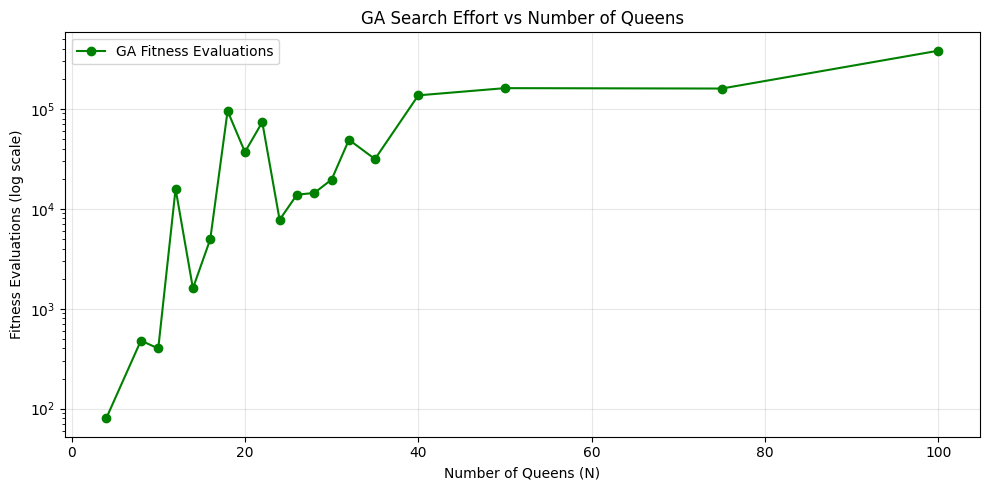

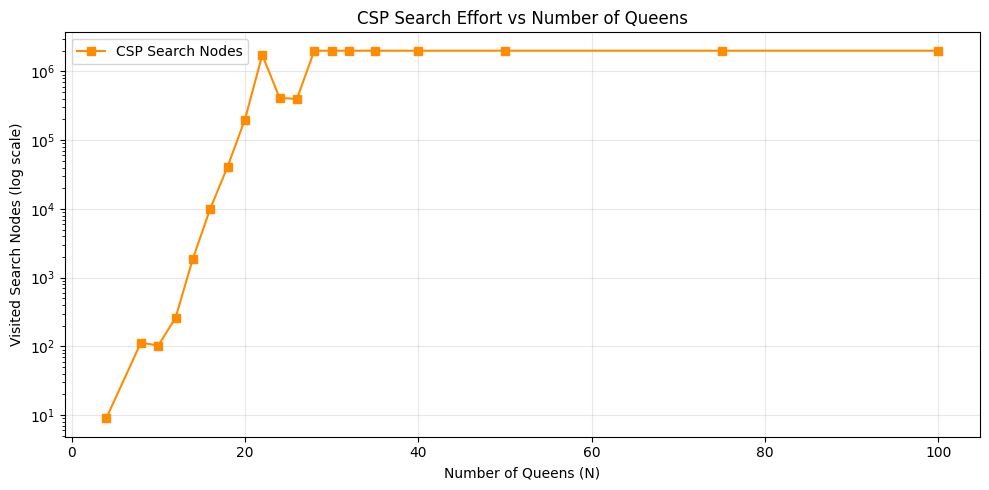

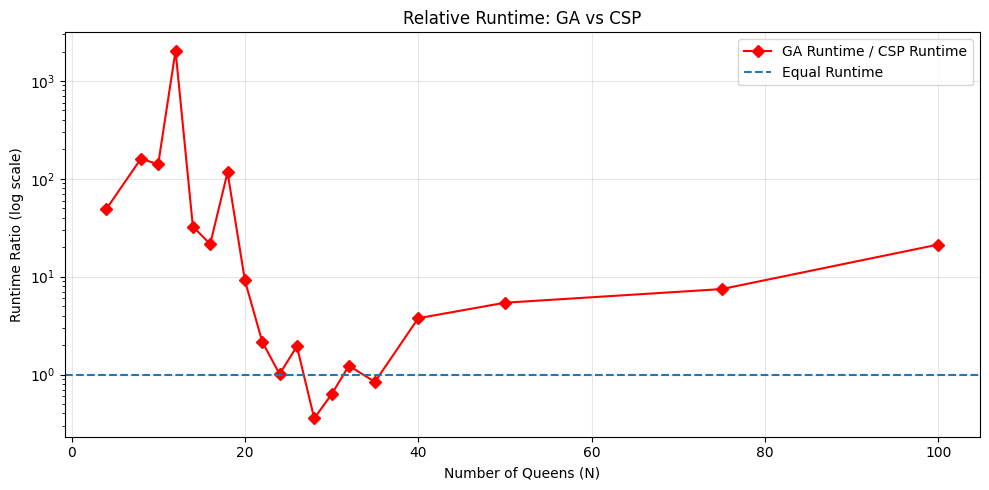

,Algorithm,Largest N Solved
0,GA,75
1,CSP,26


In [13]:

import matplotlib.pyplot as plt
import pandas as pd

# Prepare data from the existing experiment
df = results_df.copy()

ga = df[df["algorithm"] == "GA"].sort_values("N")
csp = df[df["algorithm"] == "CSP"].sort_values("N")

# -----------------------------------------
# GRAPH 1: Runtime Comparison
# -----------------------------------------
plt.figure(figsize=(10, 5))

plt.plot(ga["N"], ga["runtime_sec"], marker="o",
         label="Genetic Algorithm (GA)")
plt.plot(csp["N"], csp["runtime_sec"], marker="s",
         label="CSP / Backtracking")

plt.yscale("log")
plt.xlabel("Number of Queens (N)")
plt.ylabel("Runtime (seconds, log scale)")
plt.title("Runtime Comparison: GA vs CSP")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


# -----------------------------------------
# GRAPH 2: Search Effort Comparison
# -----------------------------------------
plt.figure(figsize=(10, 5))

plt.plot(ga["N"], ga["effort"], marker="o",
         label="GA Fitness Evaluations")
plt.plot(csp["N"], csp["effort"], marker="s",
         label="CSP Search Nodes")

plt.yscale("log")
plt.xlabel("Number of Queens (N)")
plt.ylabel("Search Effort (log scale)")
plt.title("Computational Effort: GA vs CSP")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


# -----------------------------------------
# GRAPH 3: Success / Failure Comparison
# -----------------------------------------
plt.figure(figsize=(10, 5))

plt.plot(ga["N"], ga["success"].astype(int),
         marker="o", label="GA")
plt.plot(csp["N"], csp["success"].astype(int),
         marker="s", label="CSP")

plt.yticks([0, 1], ["Failed within limits", "Solved"])
plt.ylim(-0.15, 1.15)
plt.xlabel("Number of Queens (N)")
plt.ylabel("Solution Status")
plt.title("Solution Success Comparison")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


# -----------------------------------------
# GRAPH 4: GA Generations vs Queens
# -----------------------------------------
plt.figure(figsize=(10, 5))

plt.plot(ga["N"], ga["generations"], marker="o",
         color="purple", label="GA Generations")

plt.xlabel("Number of Queens (N)")
plt.ylabel("Generations Used")
plt.title("Genetic Algorithm: Generations vs N")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


# -----------------------------------------
# GRAPH 5: Fitness Evaluations vs Queens
# -----------------------------------------
plt.figure(figsize=(10, 5))

plt.plot(ga["N"], ga["effort"], marker="o",
         color="green", label="GA Fitness Evaluations")

plt.yscale("log")
plt.xlabel("Number of Queens (N)")
plt.ylabel("Fitness Evaluations (log scale)")
plt.title("GA Search Effort vs Number of Queens")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


# -----------------------------------------
# GRAPH 6: CSP Search Nodes vs Queens
# -----------------------------------------
plt.figure(figsize=(10, 5))

plt.plot(csp["N"], csp["effort"], marker="s",
         color="darkorange", label="CSP Search Nodes")

plt.yscale("log")
plt.xlabel("Number of Queens (N)")
plt.ylabel("Visited Search Nodes (log scale)")
plt.title("CSP Search Effort vs Number of Queens")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


# -----------------------------------------
# GRAPH 7: Runtime Ratio Comparison
# -----------------------------------------
runtime_comparison = pd.merge(
    ga[["N", "runtime_sec"]],
    csp[["N", "runtime_sec"]],
    on="N",
    suffixes=("_GA", "_CSP")
)

runtime_comparison["GA_to_CSP_Ratio"] = (
    runtime_comparison["runtime_sec_GA"] /
    runtime_comparison["runtime_sec_CSP"].clip(lower=1e-9)
)

plt.figure(figsize=(10, 5))

plt.plot(
    runtime_comparison["N"],
    runtime_comparison["GA_to_CSP_Ratio"],
    marker="D",
    color="red",
    label="GA Runtime / CSP Runtime"
)

plt.axhline(y=1, linestyle="--", label="Equal Runtime")
plt.yscale("log")
plt.xlabel("Number of Queens (N)")
plt.ylabel("Runtime Ratio (log scale)")
plt.title("Relative Runtime: GA vs CSP")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


# -----------------------------------------
# FINAL: Maximum Successfully Solved N
# -----------------------------------------
summary = []

for algorithm in ["GA", "CSP"]:
    solved = df[
        (df["algorithm"] == algorithm) &
        (df["success"] == True)
    ]

    summary.append({
        "Algorithm": algorithm,
        "Largest N Solved": (
            int(solved["N"].max()) if not solved.empty else None
        )
    })

summary_df = pd.DataFrame(summary)
display(summary_df)
